# analyse textuelle
Les 30 rapports sont exploitables pour l'analyse textuelle. Ils couvrent plusieurs types de documents, notamment des rapports d'incident, des observations de terrain et des notes d'accès.

Le rapport EFR-510088 attire particulièrement notre attention : il concerne KNT-KES, est daté du 2 avril 2024 et possède un statut de diffusion restreint. Il correspond donc au site et à la période où nous avons observé une forte baisse d'activité des chauves-souris.

In [61]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

## Chargement et vérifications

In [62]:
df = pd.read_csv("environmental_field_reports_clean.csv")

In [63]:
necessaires = {'document_id', 'title', 'text'}
assert necessaires.issubset(df.columns), f'Colonnes manquantes : {necessaires - set(df.columns)}'
print('Dimensions :', df.shape)
print('Textes manquants :', df['text'].isna().sum())
display(df[['document_id', 'title', 'text']].head(3))

Dimensions : (30, 12)
Textes manquants : 0


,document_id,title,text
0,EFR-510088,Post-Access Ecological Incident at KNT-KES,INCIDENT\r\nA post-access inspection was condu...
1,EFR-510082,Field Observation 27,SITE AND TIME\r\nField observation at KNT-JAK ...
2,EFR-510035,Field Observation 28,SITE AND TIME\r\nField observation at KNT-JQG ...


## Construire le corpus

In [64]:
df['texte_original'] = (df['title'].fillna('').astype(str).str.strip() + '. ' +
                        df['text'].fillna('').astype(str).str.strip()).str.strip(' .')
docs = df.loc[df['texte_original'].str.len() > 0].copy().reset_index(drop=True)
print('Documents exploitables :', len(docs), '/', len(df))
if len(docs) < 2:
    raise ValueError('Au moins deux documents non vides sont nécessaires pour les similarités.')

def nettoyer_lexical(texte):
    texte = str(texte).lower()
    texte = re.sub(r'[^\w\s]', ' ', texte)
    texte = re.sub(r'\s+', ' ', texte).strip()
    return texte

docs['texte_prepare'] = docs['texte_original'].apply(nettoyer_lexical)
docs['nb_mots'] = docs['texte_prepare'].str.split().str.len()
display(docs[['document_id', 'nb_mots', 'texte_prepare']].head(3))

Documents exploitables : 30 / 30


,document_id,nb_mots,texte_prepare
0,EFR-510088,224,post access ecological incident at knt kes inc...
1,EFR-510082,194,field observation 27 site and time field obser...
2,EFR-510035,170,field observation 28 site and time field obser...


verifier les longueurs, types de documents et périodes

,nb_mots
count,30.000000
mean,181.600000
std,60.162768
min,110.000000
25%,139.000000
50%,170.000000
75%,201.000000
max,301.000000


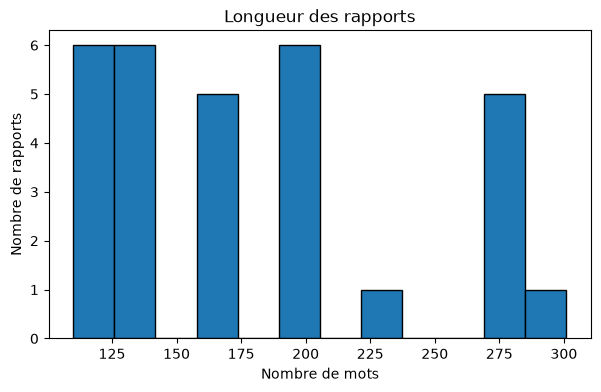


Répartition de document_type :


,effectif
document_type,
ecological_incident_report,6
field_observation,6
monitoring_report,6
cave_access_note,6
sensor_quality_report,6



Répartition de publication_status :


,effectif
publication_status,
restricted,12
public,10
internal,8



Répartition de site_code :


,effectif
site_code,
knt-dmj,3
knt-jqg,2
knt-vlb,2
knt-chp,2
knt-yrg,2
knt-wuq,2
knt-ggn,2
knt-qwu,2
knt-tlq,2


In [65]:
display(docs['nb_mots'].describe().to_frame('nb_mots'))
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(docs['nb_mots'], bins=min(12, max(3, len(docs)//2)), edgecolor='black')
ax.set(title='Longueur des rapports', xlabel='Nombre de mots', ylabel='Nombre de rapports')
plt.show()
for col in ['document_type', 'publication_status', 'site_code']:
    if col in docs.columns:
        print(f'\nRépartition de {col} :')
        display(docs[col].value_counts(dropna=False).head(15).to_frame('effectif'))

## Fréquences des mots (Bag of Words)

Taille du vocabulaire : 331


,occurrences
device,133
disturbance,99
weather,94
interval,93
monitoring,83
habitat,81
comparison,77
survey,77
access,73
bat,72


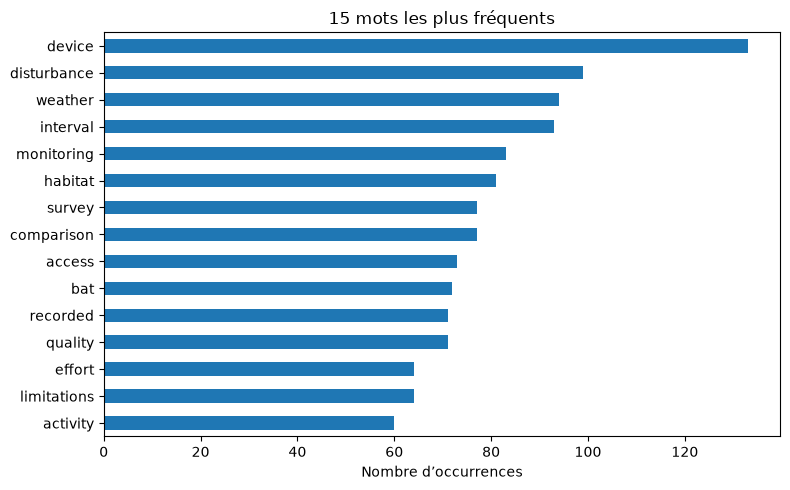

In [66]:
STOPWORDS = 'english'
vectoriseur_bow = CountVectorizer(stop_words=STOPWORDS, min_df=1)
X_bow = vectoriseur_bow.fit_transform(docs['texte_prepare'])
frequences = pd.Series(np.asarray(X_bow.sum(axis=0)).ravel(),
                       index=vectoriseur_bow.get_feature_names_out()).sort_values(ascending=False)
print('Taille du vocabulaire :', len(frequences))
display(frequences.head(20).rename('occurrences').to_frame())
frequences.head(15).sort_values().plot.barh(figsize=(8, 5), title='15 mots les plus fréquents')
plt.xlabel('Nombre d’occurrences'); plt.tight_layout(); plt.show()

N-grams : expressions fréquentes

In [67]:
vect_ng = CountVectorizer(stop_words=STOPWORDS, ngram_range=(2, 3), min_df=1)
X_ng = vect_ng.fit_transform(docs['texte_prepare'])
ngram_freq = pd.Series(np.asarray(X_ng.sum(axis=0)).ravel(),
                       index=vect_ng.get_feature_names_out()).sort_values(ascending=False)
display(ngram_freq.head(20).rename('occurrences').to_frame())

,occurrences
effort weather,64
device quality,58
recorded effort,52
recorded effort weather,52
quality limitations,52
includes recorded effort,52
device quality limitations,52
weather device,52
effort weather device,52
includes recorded,52


Les termes les plus fréquents sont liés aux dispositifs de surveillance, aux perturbations de l'habitat et aux conditions météorologiques.

Les expressions « bat activity », « habitat disturbance » et « device quality » reviennent également régulièrement.

Ces résultats montrent que les rapports abordent des facteurs pouvant influencer l'activité observée. Cependant, ces termes sont présents dans de nombreux documents et ne permettent pas, à eux seuls, d'identifier un incident particulier.

## TF-IDF : termes caractéristiques par rapport

In [68]:
vectoriseur_tfidf = TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2),
                                    min_df=1, sublinear_tf=True)
X_tfidf = vectoriseur_tfidf.fit_transform(docs['texte_prepare'])
termes = vectoriseur_tfidf.get_feature_names_out()
print('Matrice TF-IDF (documents × termes) :', X_tfidf.shape)

def termes_importants(i, n=8):
    scores = X_tfidf[i].toarray().ravel()
    indices = np.argsort(scores)[::-1][:n]
    return [(termes[j], round(float(scores[j]), 3)) for j in indices if scores[j] > 0]

for i in range(min(5, len(docs))):
    print(f"\nDocument {docs.loc[i, 'document_id']} — {docs.loc[i, 'title']}")
    print(termes_importants(i))

Matrice TF-IDF (documents × termes) : (30, 934)

Document EFR-510088 — Post-Access Ecological Incident at KNT-KES
[('post access', 0.135), ('post', 0.135), ('conducted', 0.109), ('knt kes', 0.109), ('kes', 0.109), ('cut', 0.109), ('record', 0.109), ('material', 0.109)]

Document EFR-510082 — Field Observation 27
[('cycle', 0.167), ('maintenance cycle', 0.167), ('sensor maintenance', 0.167), ('concerns sensor', 0.134), ('cycle includes', 0.134), ('sensor', 0.12), ('maintenance', 0.12), ('completed', 0.118)]

Document EFR-510035 — Field Observation 28
[('assessment', 0.201), ('disturbance assessment', 0.201), ('concerns habitat', 0.162), ('assessment includes', 0.162), ('field observation', 0.143), ('observation', 0.143), ('field', 0.143), ('0001037', 0.127)]

Document EFR-510007 — Field Observation 29
[('exception', 0.196), ('rainfall exception', 0.196), ('exception review', 0.196), ('concerns rainfall', 0.158), ('field observation', 0.139), ('observation', 0.139), ('field', 0.139), ('r

Le regroupement des rapports à partir de leur contenu textuel fait ressortir EFR-510088 dans un groupe à part.

Contrairement aux autres rapports, il se distingue par des termes associés à une intervention sur le site, notamment des traces de manipulation, du matériel coupé et une réduction marquée de l'activité après un accès en mars.

Les similarités TF-IDF avec les autres documents sont également très faibles, avec un maximum d'environ 0,092.

Le rapport EFR-510088 possède donc un contenu particulièrement différent des autres rapports étudiés. Cette singularité renforce son intérêt dans l'enquête, d'autant plus qu'il concerne précisément KNT-KES au printemps 2024.

## Similarité cosinus entre rapports

,document_1,document_2,similarite
380,EFR-510097,EFR-510053,0.878
399,EFR-510003,EFR-510110,0.866
414,EFR-510012,EFR-510060,0.852
299,EFR-510032,EFR-510011,0.795
357,EFR-510122,EFR-510008,0.792
246,EFR-510115,EFR-510042,0.786
391,EFR-510053,EFR-510110,0.781
245,EFR-510115,EFR-510019,0.777
432,EFR-510075,EFR-510130,0.773
264,EFR-510019,EFR-510042,0.769


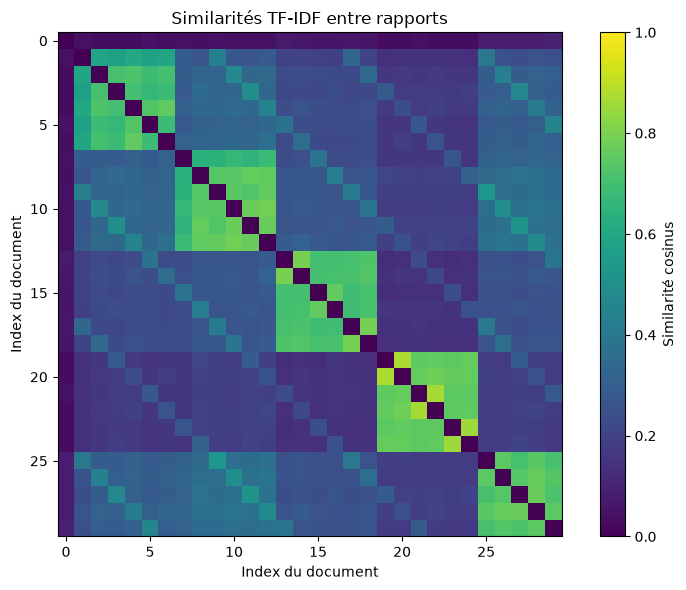

In [69]:
sim = cosine_similarity(X_tfidf)
np.fill_diagonal(sim, 0)  # Ne pas comparer un document à lui-même
paires = []
for i in range(len(docs)):
    for j in range(i + 1, len(docs)):
        paires.append({'document_1': docs.loc[i, 'document_id'],
                       'document_2': docs.loc[j, 'document_id'],
                       'similarite': sim[i, j]})
paires_df = pd.DataFrame(paires).sort_values('similarite', ascending=False)
display(paires_df.head(10).round(3))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(sim, vmin=0, vmax=1, cmap='viridis')
ax.set(title='Similarités TF-IDF entre rapports', xlabel='Index du document', ylabel='Index du document')
fig.colorbar(im, ax=ax, label='Similarité cosinus')
plt.tight_layout(); plt.show()

## Clustering exploratoire des rapports

In [70]:
from sklearn.cluster import AgglomerativeClustering

k = min(3, len(docs) - 1)
if k >= 2:
    distances = 1 - cosine_similarity(X_tfidf)
    distances = np.maximum(distances, 0)
    np.fill_diagonal(distances, 0)
    modele = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    docs['groupe_tfidf'] = modele.fit_predict(distances)
    display(docs[['document_id', 'title', 'groupe_tfidf']].sort_values('groupe_tfidf'))
    for groupe, subset in docs.groupby('groupe_tfidf'):
        print(f'\nGroupe {groupe} ({len(subset)} rapports) :')
        display(subset[['document_id', 'title']].head(10))
else:
    print('Pas assez de rapports pour créer plusieurs groupes.')

,document_id,title,groupe_tfidf
1,EFR-510082,Field Observation 27,0
2,EFR-510035,Field Observation 28,0
3,EFR-510007,Field Observation 29,0
4,EFR-510031,Field Observation 30,0
6,EFR-510048,Field Observation 32,0
5,EFR-510020,Field Observation 31,0
7,EFR-510026,Monthly Monitoring Report 33,0
8,EFR-510037,Monthly Monitoring Report 34,0
12,EFR-510042,Monthly Monitoring Report 38,0
9,EFR-510054,Monthly Monitoring Report 35,0



Groupe 0 (23 rapports) :


,document_id,title
1,EFR-510082,Field Observation 27
2,EFR-510035,Field Observation 28
3,EFR-510007,Field Observation 29
4,EFR-510031,Field Observation 30
5,EFR-510020,Field Observation 31
6,EFR-510048,Field Observation 32
7,EFR-510026,Monthly Monitoring Report 33
8,EFR-510037,Monthly Monitoring Report 34
9,EFR-510054,Monthly Monitoring Report 35
10,EFR-510115,Monthly Monitoring Report 36



Groupe 1 (1 rapports) :


,document_id,title
0,EFR-510088,Post-Access Ecological Incident at KNT-KES



Groupe 2 (6 rapports) :


,document_id,title
19,EFR-510097,Sensor Quality Review 45
20,EFR-510053,Sensor Quality Review 46
21,EFR-510003,Sensor Quality Review 47
22,EFR-510110,Sensor Quality Review 48
23,EFR-510012,Sensor Quality Review 49
24,EFR-510060,Sensor Quality Review 50


réduire la dimension du TF-IDF

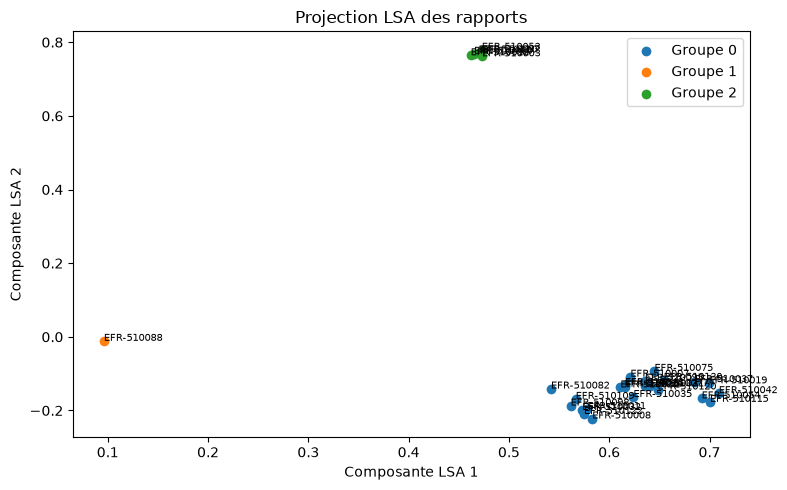

Variance expliquée (2 composantes) : 0.225


In [71]:
from sklearn.decomposition import TruncatedSVD

if min(X_tfidf.shape) >= 3:
    svd = TruncatedSVD(n_components=2, random_state=42)
    coord = svd.fit_transform(X_tfidf)
    fig, ax = plt.subplots(figsize=(8, 5))
    for g in sorted(docs['groupe_tfidf'].unique()):
        idx = docs['groupe_tfidf'].eq(g).to_numpy()
        ax.scatter(coord[idx, 0], coord[idx, 1], label=f'Groupe {g}')
    for i in range(len(docs)):
        ax.annotate(str(docs.loc[i, 'document_id']), coord[i], fontsize=7)
    ax.set(xlabel='Composante LSA 1', ylabel='Composante LSA 2', title='Projection LSA des rapports')
    ax.legend(); plt.tight_layout(); plt.show()
    print('Variance expliquée (2 composantes) :', round(svd.explained_variance_ratio_.sum(), 3))
else:
    print('Corpus trop petit pour une projection LSA à deux composantes.')

Le clustering TF-IDF isole EFR-510088 dans un groupe contenant un seul document

Identifier les mots qui distinguent chaque groupe

In [72]:
# Termes les plus caractéristiques de chaque groupe
termes = vectoriseur_tfidf.get_feature_names_out()

for groupe in sorted(docs["groupe_tfidf"].unique()):

    masque = docs["groupe_tfidf"].eq(groupe).to_numpy()

    moyenne_groupe = np.asarray(
        X_tfidf[masque].mean(axis=0)
    ).ravel()

    moyenne_autres = np.asarray(
        X_tfidf[~masque].mean(axis=0)
    ).ravel()

    difference = moyenne_groupe - moyenne_autres
    indices = np.argsort(difference)[::-1][:15]

    print(f"\nGROUPE {groupe}")
    print("Documents :", docs.loc[masque, "document_id"].tolist())
    print("Termes distinctifs :", termes[indices].tolist())


GROUPE 0
Documents : ['EFR-510082', 'EFR-510035', 'EFR-510007', 'EFR-510031', 'EFR-510020', 'EFR-510048', 'EFR-510026', 'EFR-510037', 'EFR-510054', 'EFR-510115', 'EFR-510019', 'EFR-510042', 'EFR-510032', 'EFR-510011', 'EFR-510098', 'EFR-510109', 'EFR-510122', 'EFR-510008', 'EFR-510077', 'EFR-510120', 'EFR-510075', 'EFR-510130', 'EFR-510095']
Termes distinctifs : ['access', 'habitat disturbance', 'observed', 'report', 'ordinary', 'movement', 'variation', 'seasonal', 'neighboring', 'comparison neighboring', 'neighboring sites', 'unusual count', 'organized removal', 'variation report', 'unusual']

GROUPE 1
Documents : ['EFR-510088']
Termes distinctifs : ['post', 'post access', 'material', 'cut', 'record', 'knt kes', 'conducted', 'kes', 'handling', 'material disturbed', 'moderate', 'march access', 'marked', 'marked reduction', 'march']

GROUPE 2
Documents : ['EFR-510097', 'EFR-510053', 'EFR-510003', 'EFR-510110', 'EFR-510012', 'EFR-510060']
Termes distinctifs : ['quality review', 'review'

Vérifier si les groupes correspondent aux types de rapports

In [73]:
display(
    pd.crosstab(
        docs["groupe_tfidf"],
        docs["document_type"]
    )
)

document_type,cave_access_note,ecological_incident_report,field_observation,monitoring_report,sensor_quality_report
groupe_tfidf,,,,,
0,6,5,6,6,0
1,0,1,0,0,0
2,0,0,0,0,6


Trouver les documents les plus proches du rapport suspect

In [74]:
position = np.where(
    docs["document_id"].to_numpy() == "EFR-510088"
)[0][0]

similarites_kes = cosine_similarity(
    X_tfidf[position],
    X_tfidf
).ravel()

resultats = docs[[
    "document_id",
    "title",
    "document_type",
    "site_code"
]].copy()

resultats["similarite_KES"] = similarites_kes

display(
    resultats[
        resultats["document_id"] != "EFR-510088"
    ].sort_values(
        "similarite_KES",
        ascending=False
    ).head(10)
)

,document_id,title,document_type,site_code,similarite_KES
29,EFR-510095,Ecological Incident Report 55,ecological_incident_report,knt-xac,0.091912
28,EFR-510130,Ecological Incident Report 54,ecological_incident_report,knt-bme,0.081270
25,EFR-510077,Ecological Incident Report 51,ecological_incident_report,knt-tex,0.081259
26,EFR-510120,Ecological Incident Report 52,ecological_incident_report,knt-tex,0.079153
27,EFR-510075,Ecological Incident Report 53,ecological_incident_report,knt-bme,0.077140
13,EFR-510032,Cave Access Note 39,cave_access_note,knt-dmj,0.074089
14,EFR-510011,Cave Access Note 40,cave_access_note,knt-dmj,0.063780
17,EFR-510122,Cave Access Note 43,cave_access_note,knt-qwu,0.062746
18,EFR-510008,Cave Access Note 44,cave_access_note,knt-qwu,0.061803
15,EFR-510098,Cave Access Note 41,cave_access_note,knt-ggn,0.060835


In [75]:
UTILISER_EMBEDDINGS = True

if UTILISER_EMBEDDINGS:
    from sentence_transformers import SentenceTransformer
    modele_emb = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    embeddings = modele_emb.encode(docs['texte_original'].tolist(), normalize_embeddings=True)
    sim_embeddings = cosine_similarity(embeddings)
    print('Dimensions des embeddings :', embeddings.shape)
    print('Similarité sémantique entre les deux premiers rapports :', round(float(sim_embeddings[0, 1]), 3))
else:
    print('Embeddings non exécutés : mettre UTILISER_EMBEDDINGS = True pour les tester.')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Dimensions des embeddings : (30, 384)
Similarité sémantique entre les deux premiers rapports : 0.583


Recherche d'événements suspects et de preuves textuelles

In [76]:
import re

# Motifs liés à des événements concrets
MOTIFS = {
    "traces_manipulation": r"handling marks?|tamper(?:ing|ed)?",
    "materiel_coupe": r"cut.{0,40}(?:material|restraint|strap)|(?:material|restraint|strap).{0,40}cut",
    "sediment_perturbe": r"disturbed sediment",
    "baisse_marquee": r"marked reduction|sharp decline|unusual deficit",
    "acces_maintenance": r"routine maintenance|authorized entry",
    "collecte_autorisee": r"licensed.{0,50}collection|tagging and release",
    "retrait_organise": r"organized removal",
}

resultats = []

for _, rapport in docs.iterrows():

    texte = str(rapport["texte_original"])

    # Découpage en passages
    passages = re.split(r"(?<=[.!?])\s+|\n+", texte)

    for categorie, motif in MOTIFS.items():
        for passage in passages:
            if re.search(motif, passage, flags=re.I):
                resultats.append({
                    "document_id": rapport["document_id"],
                    "site_code": rapport["site_code"],
                    "categorie": categorie,
                    "passage": passage.strip()
                })

indices_textuels = pd.DataFrame(resultats)

display(indices_textuels)

,document_id,site_code,categorie,passage
0,EFR-510088,knt-kes,traces_manipulation,Visual inspection identified fresh handling ma...
1,EFR-510088,knt-kes,materiel_coupe,Visual inspection identified fresh handling ma...
2,EFR-510088,knt-kes,materiel_coupe,"The entrance was photographed, the cut materia..."
3,EFR-510088,knt-kes,sediment_perturbe,Visual inspection identified fresh handling ma...
4,EFR-510088,knt-kes,baisse_marquee,"The acoustic station remained operational, but..."
5,EFR-510082,knt-jak,collecte_autorisee,A licensed bat collection for tagging and rele...
6,EFR-510082,knt-jak,retrait_organise,The report does not convert an unusual count i...
7,EFR-510035,knt-jqg,retrait_organise,The report does not convert an unusual count i...
8,EFR-510007,knt-jqg,retrait_organise,The report does not convert an unusual count i...
9,EFR-510031,knt-vlb,retrait_organise,The report does not convert an unusual count i...


La recherche d'expressions liées à des événements suspects fait ressortir plusieurs indices dans EFR-510088.

Le rapport mentionne des traces récentes de manipulation près d'une entrée secondaire, du matériel de retenue coupé et des sédiments perturbés sur un passage non emprunté par l'équipe de surveillance.

Ces éléments sont particulièrement importants, car ils correspondent à des traces physiques d'une possible intervention sur le site, et pas seulement à une variation des observations.

## Extraction de thèmes par rapport

In [77]:
THEMES = {
    'mention_weather': [r'weather', r'rain(?:fall|y)?', r'precipitation', r'humid(?:ity)?', r'temperature', r'wind'],
    'mention_disturbance': [r'disturbance', r'disrupt(?:ion|ed)?', r'noise', r'human activity', r'construction'],
    'mention_habitat': [r'habitat', r'vegetation', r'forest', r'woodland', r'roost', r'cave'],
    'mention_bat_activity': [r'bat(?:s)?', r'bat activity', r'acoustic activity', r'colony', r'roosting'],
    'mention_device': [r'device(?:s)?', r'sensor(?:s)?', r'detector(?:s)?', r'equipment', r'recorder(?:s)?'],
    'mention_access': [r'access', r'entrance', r'entry', r'gate', r'cave access'],
    'mention_quality': [r'quality', r'reliab(?:le|ility)', r'calibration', r'limitation(?:s)?', r'uncertainty'],
    'mention_monitoring': [r'monitoring', r'survey(?:s)?', r'follow[ -]?up', r'observation(?:s)?'],
    'mention_rainfall': [r'rain(?:fall|y)?', r'precipitation'],
    'mention_humidity': [r'humid(?:ity)?'],
    'mention_pesticide': [r'pesticide(?:s)?', r'chemical treatment'],
    'mention_sensor_failure': [r'sensor failure', r'device failure', r'equipment failure', r'malfunction', r'broken sensor', r'device outage'],
    'mention_habitat_degradation': [r'habitat degradation', r'habitat loss', r'habitat damage', r'degraded habitat'],
}

def mentionne_theme(texte, motifs):
    return int(any(re.search(r'\b(?:' + motif + r')\b', texte, flags=re.I) for motif in motifs))

for colonne, motifs in THEMES.items():
    docs[colonne] = docs['texte_prepare'].apply(lambda texte: mentionne_theme(texte, motifs))

colonnes_themes = list(THEMES)
docs['nb_themes_mentionnes'] = docs[colonnes_themes[:8]].sum(axis=1)  # 8 thèmes généraux uniquement

display(docs[['document_id'] + colonnes_themes + ['nb_themes_mentionnes']].head(10))

,document_id,mention_weather,mention_disturbance,mention_habitat,mention_bat_activity,mention_device,mention_access,mention_quality,mention_monitoring,mention_rainfall,mention_humidity,mention_pesticide,mention_sensor_failure,mention_habitat_degradation,nb_themes_mentionnes
0,EFR-510088,1,1,1,1,1,1,1,1,0,0,0,0,0,8
1,EFR-510082,1,1,1,1,1,1,1,1,0,0,1,0,0,8
2,EFR-510035,1,1,1,1,1,1,1,1,0,0,1,0,0,8
3,EFR-510007,1,1,1,1,1,1,1,1,1,0,1,0,0,8
4,EFR-510031,1,1,1,1,1,1,1,1,0,0,1,0,0,8
5,EFR-510020,1,1,1,1,1,1,1,1,0,0,1,0,0,8
6,EFR-510048,1,1,1,1,1,1,1,1,0,0,1,0,0,8
7,EFR-510026,1,1,1,1,1,1,1,1,1,0,1,0,0,8
8,EFR-510037,1,1,1,1,1,1,1,1,1,0,1,0,0,8
9,EFR-510054,1,1,1,1,1,1,1,1,1,0,1,0,0,8


Vérifier les thèmes détectés

In [78]:
bilan_themes = pd.DataFrame({
    'nb_rapports_mentionnant': docs[colonnes_themes].sum(),
    'pourcentage': (100 * docs[colonnes_themes].mean()).round(1),
}).sort_values('nb_rapports_mentionnant', ascending=False)
display(bilan_themes)

# Afficher des extraits à relire pour un thème choisi
theme_a_verifier = 'mention_disturbance'
exemples = docs.loc[docs[theme_a_verifier].eq(1), ['document_id', 'title', 'texte_original']].head(5)
for _, ligne in exemples.iterrows():
    print('\n', ligne['document_id'], '-', ligne['title'])
    print(ligne['texte_original'][:600])

,nb_rapports_mentionnant,pourcentage
mention_weather,30,100.0
mention_disturbance,30,100.0
mention_habitat,30,100.0
mention_bat_activity,30,100.0
mention_device,30,100.0
mention_quality,30,100.0
mention_monitoring,30,100.0
mention_access,25,83.3
mention_pesticide,23,76.7
mention_rainfall,13,43.3



 EFR-510088 - Post-Access Ecological Incident at KNT-KES
Post-Access Ecological Incident at KNT-KES. INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short le

 EFR-510082 - Field Observation 27
Field Observation 27. SITE AND TIME
Field observation at KNT-JAK during sensor maintenance cycle.

METHOD
The team completed a standard dusk transect and reviewed survey BAT-0001000. Effort and weather were recorded.

OBSERVATIONS
Bat activity and comparison-species counts varied across the interval. Vegetat

In [79]:
docs['nb_termes_uniques'] = docs['texte_prepare'].apply(lambda t: len(set(t.split())))
docs['diversite_lexicale'] = (docs['nb_termes_uniques'] / docs['nb_mots'].replace(0, np.nan)).fillna(0)

# Recalcul indépendant de la matrice sim modifiée précédemment pour l'affichage
sim_complete = cosine_similarity(X_tfidf)
np.fill_diagonal(sim_complete, np.nan)
docs['similarite_max'] = np.nanmax(sim_complete, axis=1)
docs['similarite_moyenne'] = np.nanmean(sim_complete, axis=1)

colonnes_resume = ['document_id', 'nb_mots', 'nb_termes_uniques', 'diversite_lexicale',
                   'nb_themes_mentionnes', 'similarite_max', 'similarite_moyenne']
if 'groupe_tfidf' in docs.columns:
    docs['cluster_tfidf'] = docs['groupe_tfidf']
    colonnes_resume.append('cluster_tfidf')
display(docs[colonnes_resume].round(3).head(10))

,document_id,nb_mots,nb_termes_uniques,diversite_lexicale,nb_themes_mentionnes,similarite_max,similarite_moyenne,cluster_tfidf
0,EFR-510088,224,153,0.683,8,0.092,0.052,1
1,EFR-510082,194,123,0.634,8,0.604,0.287,0
2,EFR-510035,170,108,0.635,8,0.724,0.332,0
3,EFR-510007,170,110,0.647,8,0.708,0.332,0
4,EFR-510031,170,107,0.629,8,0.756,0.340,0
5,EFR-510020,170,109,0.641,8,0.730,0.327,0
6,EFR-510048,170,107,0.629,8,0.756,0.329,0
7,EFR-510026,301,128,0.425,8,0.681,0.321,0
8,EFR-510037,276,117,0.424,8,0.764,0.361,0
9,EFR-510054,276,117,0.424,8,0.760,0.364,0


## Comparaison des groupes avec les catégories existantes
On vérifie si les clusters TF-IDF retrouvent simplement les document_type déjà connus, ou s’ils apportent une autre organisation. Les numéros de clusters sont arbitraires : le groupe 0 n’est pas meilleur que le groupe 1.

In [80]:
if 'cluster_tfidf' in docs.columns and 'document_type' in docs.columns:
    tableau_groupes = pd.crosstab(docs['cluster_tfidf'], docs['document_type'])
    display(tableau_groupes)
else:
    print('Comparaison impossible : cluster_tfidf ou document_type absent.')

document_type,cave_access_note,ecological_incident_report,field_observation,monitoring_report,sensor_quality_report
cluster_tfidf,,,,,
0,6,5,6,6,0
1,0,1,0,0,0
2,0,0,0,0,6


## Export du fichier enrichi

In [81]:
colonnes_a_exporter = (
    list(df.columns) + colonnes_themes +
    ['nb_mots', 'nb_termes_uniques', 'diversite_lexicale', 'nb_themes_mentionnes',
     'similarite_max', 'similarite_moyenne'] +
    [c for c in ['cluster_tfidf', 'cluster_embedding'] if c in docs.columns]
)
# Retirer les doublons éventuels dans les noms de colonnes
colonnes_a_exporter = list(dict.fromkeys(colonnes_a_exporter))
rapports_enrichis = docs[colonnes_a_exporter].copy()
assert rapports_enrichis['document_id'].is_unique, 'document_id doit être unique avant export.'
chemin_export = 'environmental_field_reports_enriched.csv'
rapports_enrichis.to_csv(chemin_export, index=False, encoding='utf-8-sig')
print('Fichier créé :', chemin_export)
print('Dimensions :', rapports_enrichis.shape)
display(rapports_enrichis.head(3))

Fichier créé : environmental_field_reports_enriched.csv
Dimensions : (30, 33)


,document_id,site_code,document_date,document_type,author_name,author_organization,reporting_period,title,text,related_survey_id,...,mention_pesticide,mention_sensor_failure,mention_habitat_degradation,nb_mots,nb_termes_uniques,diversite_lexicale,nb_themes_mentionnes,similarite_max,similarite_moyenne,cluster_tfidf
0,EFR-510088,knt-kes,2024-04-02,ecological_incident_report,Anika Dren,horizon field research cooperative,2024-04-01,Post-Access Ecological Incident at KNT-KES,INCIDENT\r\nA post-access inspection was condu...,BAT-0000064,...,0,0,0,224,153,0.683036,8,0.091912,0.051795,1
1,EFR-510082,knt-jak,2019-04-01,field_observation,Vera Waren,pollinator justice network,2019-04-01,Field Observation 27,SITE AND TIME\r\nField observation at KNT-JAK ...,BAT-0001000,...,1,0,0,194,123,0.634021,8,0.603951,0.287050,0
2,EFR-510035,knt-jqg,2022-09-08,field_observation,Uma Wessen,horizon field research cooperative,2022-09-01,Field Observation 28,SITE AND TIME\r\nField observation at KNT-JQG ...,BAT-0001037,...,1,0,0,170,108,0.635294,8,0.724155,0.332152,0


In [82]:
terms=["incident","unusual","unexpected","access","restricted","failure","tamper","damage","decline","disturbance","cut","missing","inconsisten"]
pattern="|".join(terms)
mask=(df["title"].fillna("")+" "+df["text"].fillna("")).str.contains(pattern,case=False,regex=True)
display(df.loc[mask,["document_id","site_code","document_date","title","publication_status","related_survey_id"]].sort_values("document_date"))
print("Attention : ces mots sont des pistes, pas une preuve d'incident.")

,document_id,site_code,document_date,title,publication_status,related_survey_id
22,EFR-510110,knt-ujj,2018-01-13,Sensor Quality Review 48,restricted,BAT-0001777
6,EFR-510048,knt-chp,2018-05-09,Field Observation 32,internal,BAT-0001185
14,EFR-510011,knt-dmj,2018-09-11,Cave Access Note 40,restricted,BAT-0001481
1,EFR-510082,knt-jak,2019-04-01,Field Observation 27,restricted,BAT-0001000
25,EFR-510077,knt-tex,2019-04-07,Ecological Incident Report 51,internal,BAT-0001888
9,EFR-510054,knt-yrg,2019-08-03,Monthly Monitoring Report 35,public,BAT-0001296
17,EFR-510122,knt-qwu,2019-12-05,Cave Access Note 43,restricted,BAT-0001592
20,EFR-510053,knt-tlq,2020-03-26,Sensor Quality Review 46,restricted,BAT-0001703
28,EFR-510130,knt-bme,2020-07-01,Ecological Incident Report 54,restricted,BAT-0001999
4,EFR-510031,knt-vlb,2020-07-22,Field Observation 30,internal,BAT-0001111


Attention : ces mots sont des pistes, pas une preuve d'incident.


In [83]:
import re
rows=[]
for _,r in df.iterrows():
 sentences=re.split(r"(?<=[.!?])\s+|\n+",str(r.get("text", "")))
 for sent in sentences:
  found=[term for term in terms if re.search(re.escape(term),sent,re.I)]
  if found:
   rows.append({"document_id":r.document_id,"site_code":r.site_code,"document_date":r.document_date,"termes":", ".join(found),"extrait":sent.strip()[:450]})
passages=pd.DataFrame(rows)
print("Passages candidats :",len(passages))
display(passages.head(35))

Passages candidats : 173


,document_id,site_code,document_date,termes,extrait
0,EFR-510088,knt-kes,2024-04-02,incident,INCIDENT
1,EFR-510088,knt-kes,2024-04-02,access,A post-access inspection was conducted at KNT-...
2,EFR-510088,knt-kes,2024-04-02,cut,Visual inspection identified fresh handling ma...
3,EFR-510088,knt-kes,2024-04-02,access,The access register confirms authorized equipm...
4,EFR-510088,knt-kes,2024-04-02,cut,"The entrance was photographed, the cut materia..."
5,EFR-510088,knt-kes,2024-04-02,access,The access authority was asked to preserve the...
6,EFR-510088,knt-kes,2024-04-02,disturbance,"Seasonal movement, unrecorded disturbance, and..."
7,EFR-510088,knt-kes,2024-04-02,access,The report therefore records an unexplained po...
8,EFR-510082,knt-jak,2019-04-01,"access, cut",Vegetation and access conditions showed no acu...
9,EFR-510082,knt-jak,2019-04-01,disturbance,Bat activity was interpreted alongside habitat...


In [84]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
corpus=df["text"].fillna("").astype(str)
vectorizer=TfidfVectorizer(stop_words="english",ngram_range=(1,2),min_df=1)
X=vectorizer.fit_transform(corpus)
S=cosine_similarity(X);np.fill_diagonal(S,-1)
rows=[]
for i in range(len(df)):
 j=int(S[i].argmax())
 rows.append({"document_id":df.iloc[i].document_id,"rapport_proche":df.iloc[j].document_id,"similarite":S[i,j],"site_code":df.iloc[i].site_code})
display(pd.DataFrame(rows).sort_values("similarite",ascending=False).head(20))
print("Une forte similarité peut simplement provenir d'un modèle de rapport commun.")

,document_id,rapport_proche,similarite,site_code
19,EFR-510097,EFR-510053,0.937477,knt-tlq
20,EFR-510053,EFR-510097,0.937477,knt-tlq
22,EFR-510110,EFR-510003,0.927144,knt-ujj
21,EFR-510003,EFR-510110,0.927144,knt-ujj
24,EFR-510060,EFR-510012,0.905944,knt-vxr
23,EFR-510012,EFR-510060,0.905944,knt-vxr
13,EFR-510032,EFR-510011,0.803597,knt-dmj
14,EFR-510011,EFR-510032,0.803597,knt-dmj
17,EFR-510122,EFR-510008,0.792543,knt-qwu
18,EFR-510008,EFR-510122,0.792543,knt-qwu


Une forte similarité peut simplement provenir d'un modèle de rapport commun.


Analyse détaillée du rapport EFR-510088

In [85]:
# Retrouver le rapport suspect
rapport = df.loc[df["document_id"] == "EFR-510088"]

if len(rapport) == 1:
    r = rapport.iloc[0]

    print("Document :", r["document_id"])
    print("Site :", r["site_code"])
    print("Date :", r["document_date"])
    print("Relevé associé :", r["related_survey_id"])
    print("Statut :", r["publication_status"])

    print("\nCONTENU DU RAPPORT :\n")
    print(r["text"])
else:
    print("Rapport absent ou identifiant non unique.")

Document : EFR-510088
Site : knt-kes
Date : 2024-04-02
Relevé associé : BAT-0000064
Statut : restricted

CONTENU DU RAPPORT :

INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.

IMMEDIATE ACTION
The entrance was photographed, the cut material w

In [86]:
ids = ["EFR-510088", "EFR-510082", "EFR-510026"]

comparaison = df[df["document_id"].isin(ids)]

for _, r in comparaison.iterrows():
    print("\n" + "=" * 60)
    print("Document :", r["document_id"])
    print("Site :", r["site_code"])
    print("Type :", r["document_type"])
    print("Statut :", r["publication_status"])
    print("\nTexte :")
    print(r["text"])


Document : EFR-510088
Site : knt-kes
Type : ecological_incident_report
Statut : restricted

Texte :
INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.

IMMEDIATE ACTION
The entrance was photographed, the cut material was retained, and the stati

### Bilan des analyses et hypothèse retenue

L'analyse des 30 rapports fait ressortir un document : **EFR-510088, daté du 2 avril 2024 et concernant le site KNT-KES**.

Plusieurs éléments permettent de le distinguer des autres rapports :

- **Un contenu textuel atypique :** le clustering TF-IDF isole EFR-510088 dans un groupe à part. Le rapport contient des expressions liées à des manipulations, du matériel coupé et une diminution marquée de l'activité.
- **Une espèce particulièrement touchée :** le rapport signale une baisse importante de l'activité d'*Eonycteris spelaea* après un accès au site en mars 2024.
- **Des traces physiques inexpliquées :** le rapport mentionne des marques de manipulation près d'une entrée secondaire, du matériel de retenue coupé et des sédiments perturbés sur un passage non emprunté par l'équipe de surveillance.
- **Une chronologie suspecte :** ces observations sont rapportées après un accès au site enregistré comme une opération de maintenance ordinaire.
- **Une explication technique insuffisante :** les dispositifs acoustiques étaient opérationnels, avec une disponibilité supérieure à 90 %, et aucune panne prolongée n'avait été constatée.

Ces éléments sont particulièrement suspects car le rapport associe une baisse d'activité touchant une espèce précise à des traces matérielles suggérant une intervention humaine.

**Hypothèse retenue :** une intervention humaine aurait pu avoir lieu à KNT-KES lors de la période d'accès de mars 2024, sous couvert d'une opération de maintenance. Cette intervention pourrait avoir entraîné une perturbation, un déplacement ou un retrait non documenté d'individus de l'espèce *Eonycteris spelaea*.

